# OSM floorplan decomposition pipeline

**Objective**
Load the cleaned OSM working subset exported by the preprocessing notebook and continue with optional perimeter preparation plus convex decomposition diagnostics.

**Source credit**
The input footprints are derived from OpenStreetMap contributors data and redistributed here in anonymized reduced form under ODbL 1.0. `ConvexDecomp` contributes the workflow and decomposition code, not the underlying source dataset.

**Inputs**
- `data/osm/subset_buildings_gdf.pkl` produced by `OSM_1_Preprocessing.ipynb`

**Workflow overview**
1. Load the preprocessed OSM decomposition working set.
2. Optionally split footprints into perimeter and interior zones before decomposition.
3. Run the shared convex decomposition workflow and collect case-level diagnostics.
4. Inspect representative successful and failed outcomes across the footprint-complexity range.


### Configure notebook environment
Set project paths and import the reusable OSM helpers used by the decomposition workflow.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython

from shapely.geometry import MultiPolygon, Polygon
from shapely.geometry.base import BaseGeometry

ip = get_ipython()
# OSM benefits from widget plots when ipympl is available.
if ip is not None:
    try:
        ip.run_line_magic('matplotlib', 'widget')
    except Exception:
        ip.run_line_magic('matplotlib', 'inline')

from convexdecomp.notebook_utils import find_project_root

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
OSM_DATA_DIR = PROJECT_ROOT / 'data' / 'osm'
SUBSET_BUILDINGS_PATH = OSM_DATA_DIR / 'subset_buildings_gdf.pkl'

SRC_DIR = PROJECT_ROOT / 'src'

for extra_path in (PROJECT_ROOT, SRC_DIR):
    if str(extra_path) not in sys.path:
        sys.path.insert(0, str(extra_path))

from convexdecomp.plotting.geometry_grid import GHSL_gridplot
from convexdecomp.plotting.polygons import fill_polygon_geometry, set_geometry_frame
from convexdecomp.core.search import AdaptiveSearchConfig
from convexdecomp.osm.decompose import ConvexDecompositionConfig
from convexdecomp.osm.diagnostics import (
    annotate_polygon_failure_reasons,
    parts_from_geom,
    prepare_decomposition_inputs,
    run_building_decomposition,
    select_complexity_ids,
    summarize_building_decomposition,
)
from convexdecomp.osm.perimeter import (
    PerimeterConfig,
    build_perimeter_zones_for_gdf,
    summarize_perimeter_results,
)
from convexdecomp.osm.subdivide import PerimeterSubdivisionConfig

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['axes.titlesize'] = 10


### Load the preprocessed OSM subset and inspect input diagnostics

**Inputs**
- `data/osm/subset_buildings_gdf.pkl` from `OSM_1_Preprocessing.ipynb`
- Shared helper `convexdecomp.diagnostics.datasets`

**Steps**
1. Load the OSM working subset used by the rest of the notebook.
2. Report how many input polygons the subset contains and how many are already concave.
3. Count how many samples contain at least one polygon below `2.0 m^2`.
4. Plot a compact row of input-distribution diagnostics before perimeter preprocessing and convex decomposition.

**Outputs**
- `subset_buildings_gdf`
- Printed input-dataset diagnostics and a diagnostic plot row

subset_buildings_gdf shape: (2755, 5)
columns: ['sample_id', 'geometry', 'area_m2', 'n_vertices', 'n_holes']

=== OSM input diagnostics ===
Samples in working set: 2755
Polygons across all samples: 2755
Concave polygons before convex decomposition: 2755 / 2755 (100.0%)
Samples with at least one polygon below 2.0 m^2: 0 / 2755 (0.0%)


,sample_id,geometry,area_m2,n_vertices,n_holes
13,osm_0014,"POLYGON ((10.921 10.674, 15.242 0.178, 5.782 -...",258.534715,16,0
14,osm_0015,"POLYGON ((-6.436 -0.491, 3.511 4.774, 6.078 -0...",57.848245,6,0
18,osm_0019,"POLYGON ((1.202 5.761, 5.61 -0.752, -1.827 -5....",64.836688,6,0
20,osm_0021,"POLYGON ((6.172 -3.52, 4.123 -5.271, 2.89 -4.9...",119.711612,13,0
22,osm_0023,"POLYGON ((-5.06 -8.831, -7.923 -5.657, -1.369 ...",106.032904,6,0


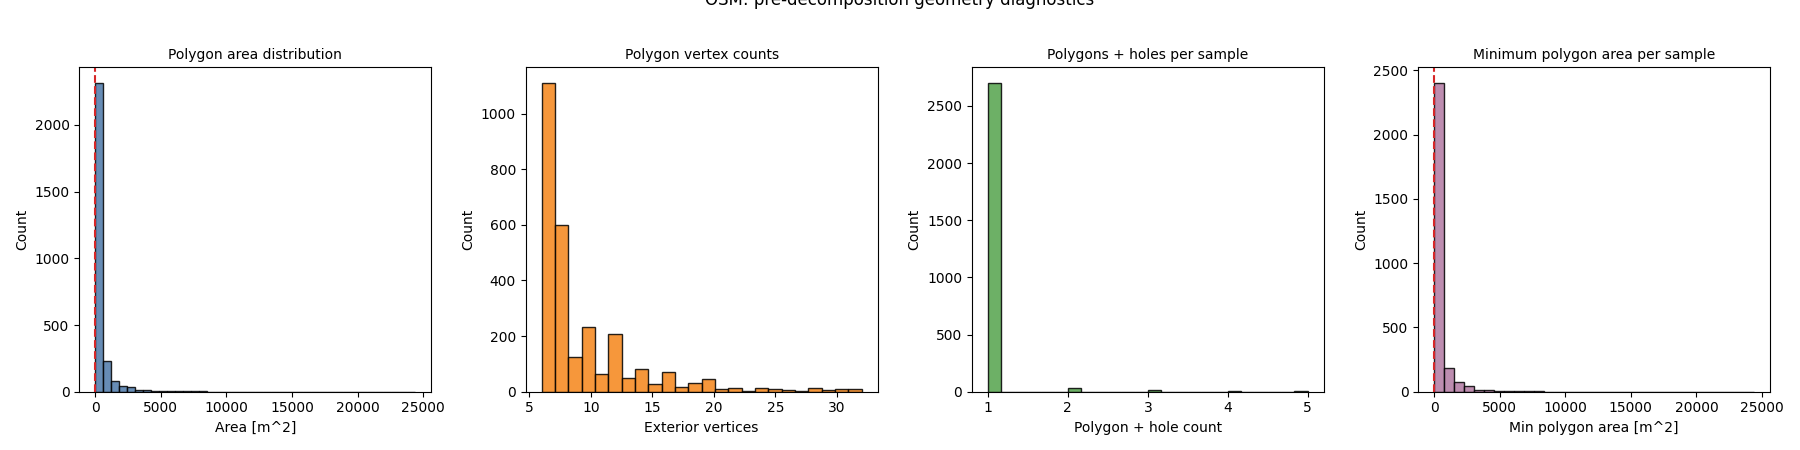

In [2]:
if not SUBSET_BUILDINGS_PATH.exists():
    raise FileNotFoundError(
        f'Missing {SUBSET_BUILDINGS_PATH}. Run OSM_1_Preprocessing.ipynb first to create the preprocessed subset.'
    )

subset_buildings_gdf = pd.read_pickle(SUBSET_BUILDINGS_PATH)

from convexdecomp.diagnostics.datasets import (
    plot_osm_input_dataset_diagnostics,
)

print('subset_buildings_gdf shape:', subset_buildings_gdf.shape)
print('columns:', subset_buildings_gdf.columns.tolist())
print('')
input_diag_summary, input_diag_df = plot_osm_input_dataset_diagnostics(
    subset_buildings_gdf,
    polygons_col='geometry',
    sample_id_col='sample_id',
    min_area_m2=2.0,
    dataset_label='OSM',
)
subset_buildings_gdf.head()


### Configure perimeter zoning parameters
Keep the OSM perimeter builder aligned with the current probe-based interior rule used in the active helper module.


In [3]:
PERIMETER_CFG = PerimeterConfig(
    perimeter_depth_m=4.5,
    min_zone_edge_m=2.0,
    min_zone_area_m2=4.0,
    min_interior_edge_m=2.0,
    min_interior_area_m2=4.0,
    min_input_area_m2=2.0,
    interior_probe_offset_m=0.5,
    simplify_tolerance_m=0.001,
    min_contact_groups=2,
    min_contact_group_length_m=0.5,
    contact_turn_angle_deg=35.0,
    enforce_input_edge_threshold=False,
)

PERIMETER_CFG


PerimeterConfig(perimeter_depth_m=4.5, min_zone_edge_m=2.0, min_zone_area_m2=4.0, min_interior_edge_m=2.0, min_interior_area_m2=4.0, interior_opening_m=0.5, interior_simplify_tolerance_m=0.0, min_input_area_m2=2.0, interior_probe_offset_m=0.5, interior_min_edge_cleanup_m=0.1, simplify_tolerance_m=0.001, eps_m=0.01, min_contact_groups=2, min_contact_group_length_m=0.5, contact_turn_angle_deg=35.0, enforce_input_edge_threshold=False, split_perimeter_holes=True, area_tol=1e-06, join_style=2, offset_match_angle_tol_deg=5.0, offset_match_distance_tol_m=0.5)

### Build perimeter zoning results and inspect successful split cases

**Inputs**
- `subset_buildings_gdf` with the working OSM sample in `geometry`
- `PERIMETER_CFG` with the perimeter depth, probe offset, and interior-validity thresholds

**Steps**
1. Run the module-backed perimeter zoning pipeline on every building footprint.
2. Store the returned `perimeter_geom`, `interior_geom`, exact offset matches, and diagnostics on `subset_buildings_gdf`.
3. Summarize how many buildings end up as `perimeter + interior`, `perimeter only`, or `no perimeter zoning`.
4. Plot a compact count summary and the detailed reason breakdown.
5. Use `GHSL_gridplot` to overlay original footprints, perimeter shells, and retained interior cores for a small sample of successful split cases.

**Outputs**
- Updated `subset_buildings_gdf` with perimeter zoning columns
- `perimeter_summary` with aggregate counts and reason frequencies
- Gridplots for buildings where a split perimeter/core zoning was retained

**Used functions**
`build_perimeter_zones_for_gdf`, `summarize_perimeter_results`, `GHSL_gridplot`


Perimeter zoning summary:
Total buildings: 2755
Perimeter + interior: 1266
Perimeter only: 1489
No perimeter zoning: 0

Reason counts:
perimeter_with_interior                  1266
perimeter_only_no_nominal_interior       1198
perimeter_only_all_interiors_absorbed     291


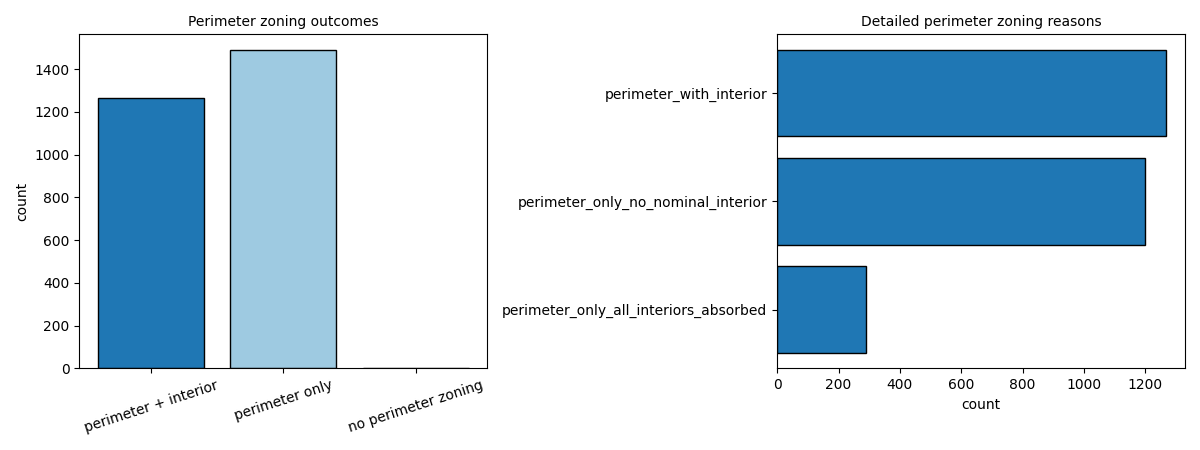

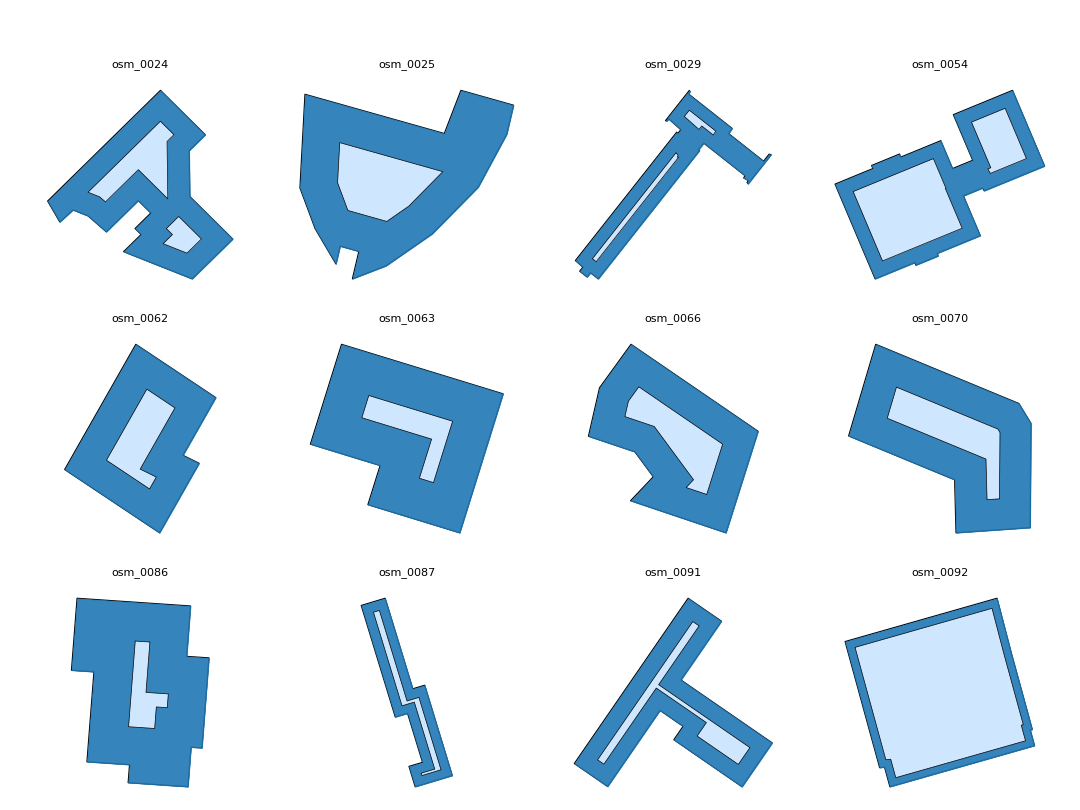

In [4]:
N_SHOW_PERIM = 12

subset_buildings_gdf = build_perimeter_zones_for_gdf(
    subset_buildings_gdf,
    geometry_col='geometry',
    cfg=PERIMETER_CFG,
)
perimeter_summary = summarize_perimeter_results(subset_buildings_gdf)

print('Perimeter zoning summary:')
print(f"Total buildings: {perimeter_summary['n_total']}")
print(f"Perimeter + interior: {perimeter_summary['n_with_interior']}")
print(f"Perimeter only: {perimeter_summary['n_perimeter_only']}")
print(f"No perimeter zoning: {perimeter_summary['n_no_perimeter_defined']}")
print('')
print('Reason counts:')
print(pd.Series(perimeter_summary['reason_counts']).to_string())

summary_plot_df = pd.DataFrame(
    {
        'category': ['perimeter + interior', 'perimeter only', 'no perimeter zoning'],
        'count': [
            perimeter_summary['n_with_interior'],
            perimeter_summary['n_perimeter_only'],
            perimeter_summary['n_no_perimeter_defined'],
        ],
    }
)
reason_plot = pd.Series(perimeter_summary['reason_counts']).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(summary_plot_df['category'], summary_plot_df['count'], color=['#1f77b4', '#9ecae1', '#d9d9d9'], edgecolor='black')
axes[0].set_title('Perimeter zoning outcomes')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=18)

axes[1].barh(reason_plot.index, reason_plot.values, color='#1f77b4', edgecolor='black')
axes[1].set_title('Detailed perimeter zoning reasons')
axes[1].set_xlabel('count')

plt.tight_layout()
plt.show()

perim_ids = (
    subset_buildings_gdf.loc[subset_buildings_gdf['perimeter'], 'sample_id']
    .dropna()
    .head(N_SHOW_PERIM)
    .tolist()
)

if not perim_ids:
    print('No buildings retained a split perimeter + interior zoning under the current configuration.')
else:
    bsub = subset_buildings_gdf.loc[subset_buildings_gdf['sample_id'].isin(perim_ids)].copy()
    bsub_outline = gpd.GeoDataFrame(bsub, geometry='geometry', crs=subset_buildings_gdf.crs)
    bsub_perimeter = gpd.GeoDataFrame(bsub, geometry='perimeter_geom', crs=subset_buildings_gdf.crs)
    bsub_interior = gpd.GeoDataFrame(
        bsub.loc[bsub['interior_geom'].notna()].copy(),
        geometry='interior_geom',
        crs=subset_buildings_gdf.crs,
    )

    GHSL_gridplot(
        [
            {
                'name': 'building_outline',
                'gdf': bsub_outline,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.9,
                'zorder': 1,
            },
            {
                'name': 'perimeter_geom',
                'gdf': bsub_perimeter,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'perimeter_geom',
                'color': '#1f77b4',
                'edgecolor': '#1f77b4',
                'linewidth': 0.5,
                'alpha': 0.9,
                'zorder': 2,
            },
            {
                'name': 'interior_geom',
                'gdf': bsub_interior,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'interior_geom',
                'color': '#cfe6ff',
                'edgecolor': 'black',
                'linewidth': 0.5,
                'alpha': 1.0,
                'zorder': 3,
            },
        ],
        ids=perim_ids,
        ncols=4,
        figsize_scale=2.7,
        title_fn=lambda sid, i: str(sid),
    )


## Prepare convex decomposition inputs


### Configure optional trapezoid-triangle pre-check
Set `USE_TRAPEZOID_TRIANGLE_PRECHECK=True` to extract matched trapezoids and corner triangles from perimeter zones before the general convex decomposition runs.


In [5]:
USE_TRAPEZOID_TRIANGLE_PRECHECK = True

PRECHECK_SUBDIV_CFG = PerimeterSubdivisionConfig(
    min_trapezoid_area_m2=4.0,
    simplify_tolerance_m=0.001,
)

{
    'USE_TRAPEZOID_TRIANGLE_PRECHECK': USE_TRAPEZOID_TRIANGLE_PRECHECK,
    'PRECHECK_SUBDIV_CFG': PRECHECK_SUBDIV_CFG,
}


{'USE_TRAPEZOID_TRIANGLE_PRECHECK': True,
 'PRECHECK_SUBDIV_CFG': PerimeterSubdivisionConfig(min_trapezoid_area_m2=4.0, simplify_tolerance_m=0.001)}

### Prepare polygon inputs for decomposition

**Inputs**
- `subset_buildings_gdf` after perimeter zoning
- `USE_TRAPEZOID_TRIANGLE_PRECHECK` and `PRECHECK_SUBDIV_CFG`

**Steps**
1. Build the default polygon list for each building from `perimeter_parts + interior_geom`, or the original footprint when no perimeter zoning exists.
2. Optionally run `subdivide_perimeter_gdf` to extract matched trapezoids, corner triangles, and leftover perimeter remainders before decomposition.
3. Store the final per-building polygon list in `decomp_polygons` and summarize the resulting polygon and vertex counts.

**Outputs**
- `buildings_convex_gdf` with prepared `decomp_polygons`
- Optional `trapezoid_seed_gdf`, `corner_seed_gdf`, and `remainder_seed_gdf`

**Used functions**
`subdivide_perimeter_gdf`, `extract_polygons`


In [6]:
buildings_convex_gdf, trapezoid_seed_gdf, corner_seed_gdf, remainder_seed_gdf = prepare_decomposition_inputs(
    subset_buildings_gdf,
    use_trapezoid_triangle_precheck=USE_TRAPEZOID_TRIANGLE_PRECHECK,
    precheck_subdiv_cfg=PRECHECK_SUBDIV_CFG,
)

print('Buildings prepared for decomposition:', len(buildings_convex_gdf))
print('Perimeter-defined buildings:', int(buildings_convex_gdf['perimeter_defined'].fillna(False).sum()))
print('Split perimeter + interior buildings:', int(buildings_convex_gdf['perimeter'].fillna(False).sum()))
print('Perimeter-only buildings:', int(buildings_convex_gdf['perimeter_only'].fillna(False).sum()))
print('No perimeter zoning buildings:', int((~buildings_convex_gdf['perimeter_defined'].fillna(False)).sum()))
print(f"Mean decomposition input polygons per building: {buildings_convex_gdf['n_polygons'].mean():.2f}")
print(f"Mean decomposition input vertices per building: {buildings_convex_gdf['n_vertices'].mean():.2f}")

if USE_TRAPEZOID_TRIANGLE_PRECHECK:
    print('')
    print('Perimeter pre-check summary:')
    print(f'Trapezoid seeds: {len(trapezoid_seed_gdf)}')
    print(f'Corner-triangle seeds: {len(corner_seed_gdf)}')
    print(f'Remainder perimeter seeds: {len(remainder_seed_gdf)}')
    print(buildings_convex_gdf['trapezoid_subdivision_reason'].fillna('missing').value_counts().to_string())
else:
    print('')
    print('Perimeter pre-check summary: disabled (direct decomposition of perimeter parts and interiors).')


Buildings prepared for decomposition: 2755
Perimeter-defined buildings: 2755
Split perimeter + interior buildings: 1266
Perimeter-only buildings: 1489
No perimeter zoning buildings: 0
Mean decomposition input polygons per building: 3.28
Mean decomposition input vertices per building: 20.18

Perimeter pre-check summary:
Trapezoid seeds: 4696
Corner-triangle seeds: 155
Remainder perimeter seeds: 2772
trapezoid_subdivision_reason
insufficient_exact_vertex_matches               1198
matched_trapezoids                              1065
discarded_small_interior_kept_as_single_zone     243
insufficient_consecutive_matches                 118
matched_trapezoids_and_corners                    98
collapsed_corner_parts                            33


### Configure the convex decomposer
Set the polygon-wise decomposer parameters and adaptive retry schedule used on the prepared decomposition inputs.


In [7]:
cfg = ConvexDecompositionConfig(
    search_depth=24,
    search_width=4,
    max_reflex_per_node=8,
    max_variants_per_polygon=32,
    max_failed_states=500,
    track_time=True,
    min_area_m2=2.0,
    weight_parts=1.0,
    weight_compactness=20.0,
    adaptive_search=AdaptiveSearchConfig(
        enabled=True,
        initial_depth=4,
        initial_width=3,
        max_depth=24,
        max_width=4,
        depth_step=1,
        width_step=1,
    ),
)

cfg


ConvexDecompositionConfig(search_depth=24, search_width=4, max_variants_per_polygon=32, max_failed_states=500, min_area_m2=2.0, weight_parts=1.0, weight_compactness=20.0, min_concavity_deg=2.0, max_reflex_per_node=8, length_factor=10.0, track_time=True, use_bisector_dead_end_fallback=True, cut_snap_vertex_tolerance_m=0.1, adaptive_search=AdaptiveSearchConfig(enabled=True, initial_depth=4, initial_width=3, max_depth=24, max_width=4, depth_step=1, width_step=1))

## Run convex decomposition

**Inputs**
- `buildings_convex_gdf` with `decomp_polygons`, `n_polygons`, and `n_vertices`
- `cfg` with the convex decomposition search depth, width, adaptive retry schedule, and scoring weights

**Steps**
1. Read the prepared polygon list for each building from `decomp_polygons`.
2. Run `decompose_polygon_with_stats` on each polygon, starting from a cheap search setting and retrying with larger depth, then width, until the first successful parameter setting is found.
3. Collect the returned convex pieces, timings, retry diagnostics, and success flags back to building level.
4. Store the merged convex output geometry in `convex_parts_geom` for later summaries and plots.

**Outputs**
- `buildings_convex_gdf` enriched with per-building convex decomposition results
- `results_df` with counts, flags, timings, retry diagnostics, and output geometries

**Used functions**
`decompose_polygon_with_stats`


In [8]:
buildings_convex_gdf, results_df, polygon_results_gdf = run_building_decomposition(buildings_convex_gdf, cfg)
buildings_convex_gdf.head()


,sample_id,geometry,area_m2,n_vertices,n_holes,processed,perimeter_defined,perimeter,has_interior,perimeter_only,...,polygon_search_depths_used,polygon_search_widths_used,polygon_search_attempt_counts,n_failed_polygons,n_small_zone_polygons,n_retried_polygons,total_search_attempts,max_search_depth_used,max_search_width_used,time_total_seconds
13,osm_0014,"POLYGON ((10.921 10.674, 15.242 0.178, 5.782 -...",258.534715,16,0,True,True,False,False,True,...,[6],[3],[3],0,0,1,3,6,3,0.064403
14,osm_0015,"POLYGON ((-6.436 -0.491, 3.511 4.774, 6.078 -0...",57.848245,6,0,True,True,False,False,True,...,[4],[3],[1],0,0,0,1,4,3,0.004042
18,osm_0019,"POLYGON ((1.202 5.761, 5.61 -0.752, -1.827 -5....",64.836688,6,0,True,True,False,False,True,...,[4],[3],[1],0,0,0,1,4,3,0.003529
20,osm_0021,"POLYGON ((6.172 -3.52, 4.123 -5.271, 2.89 -4.9...",119.711612,13,0,True,True,False,False,True,...,[4],[3],[1],0,0,0,1,4,3,0.033995
22,osm_0023,"POLYGON ((-5.06 -8.831, -7.923 -5.657, -1.369 ...",106.032904,6,0,True,True,False,False,True,...,[4],[3],[1],0,0,0,1,4,3,0.002795


### Check that no area went missing

Every stage after preprocessing must hand on the footprint's full area: the perimeter band and core, the polygons handed to the decomposer, and the convex parts. Each building carries one error per stage (`perimeter_area_error_m2`, `inputs_area_error_m2`, `parts_area_error_m2`, all against the footprint), and the check stops the notebook if any of them exceeds a millionth of the footprint area. A failed decomposition is not a violation: it has no parts to check.

**Inputs**
- `buildings_convex_gdf` from the decomposition run

**Outputs**
- nothing new; the notebook stops here if a building changed area

**Used functions**
`check_area_conservation`

In [ ]:
from convexdecomp.osm.diagnostics import check_area_conservation

check_area_conservation(buildings_convex_gdf)

n_checked = int(buildings_convex_gdf['building_fully_convex'].fillna(False).sum())
largest = buildings_convex_gdf['parts_area_error_m2'].abs().max()
print(f'Area kept at every stage for all {n_checked} fully convex buildings (largest error {largest:.1e} m^2).')

## Summarize decomposition results

**Inputs**
- `buildings_convex_gdf` with per-building convex decomposition results and adaptive-search diagnostics

**Steps**
1. Count how many individual polygons across all buildings reached a fully convex best variant.
2. Count how many whole buildings have every polygon fully convex.
3. Report the share of buildings that contain any convex part smaller than `cfg.min_area_m2`.
4. Summarize the typical number of convex parts, retry attempts, selected search depths, and runtime per building.

**Outputs**
- Printed convex decomposition summary for the current OSM working set


In [9]:
summary = summarize_building_decomposition(buildings_convex_gdf, min_area_m2=cfg.min_area_m2)

print('=== Convex decomposition summary ===')
print(f"Buildings in working set: {int(summary['n_buildings_total'])}")
print(f"Polygons across all buildings: {int(summary['n_polygons_total'])}")
print(f"Polygons with fully convex decomposition: {int(summary['n_polygons_success'])} ({100.0 * int(summary['n_polygons_success']) / max(int(summary['n_polygons_total']), 1):.1f}%)")
print(f"Buildings with all polygons fully convex: {int(summary['n_buildings_success'])} ({100.0 * int(summary['n_buildings_success']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Buildings with at least one failed polygon decomposition: {int(summary['n_buildings_failed'])} ({100.0 * int(summary['n_buildings_failed']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Buildings with any zone smaller than {cfg.min_area_m2:.1f} m²: {int(summary['n_small_zone'])} ({100.0 * int(summary['n_small_zone']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Polygons that needed at least one retry: {int(summary['n_polygons_retried'])} ({100.0 * int(summary['n_polygons_retried']) / max(int(summary['n_polygons_total']), 1):.1f}%)")
print(f"Mean convex parts per building: {float(summary['parts_per_building_mean']):.2f}")
print(f"Median convex parts per building: {float(summary['parts_per_building_median']):.2f}")
print(f"Mean search attempts per polygon: {float(summary['mean_attempts_per_polygon']):.2f}")
print(f"Max selected search depth: {int(summary['max_search_depth_used'])}")
print(f"Max selected search width: {int(summary['max_search_width_used'])}")
print(f"Mean decomposition time per building: {float(summary['mean_time_seconds']):.4f} s")


=== Convex decomposition summary ===
Buildings in working set: 2755
Polygons across all buildings: 9026
Polygons with fully convex decomposition: 8969 (99.4%)
Buildings with all polygons fully convex: 2699 (98.0%)
Buildings with at least one failed polygon decomposition: 56 (2.0%)
Buildings with any zone smaller than 2.0 m²: 0 (0.0%)
Polygons that needed at least one retry: 603 (6.7%)
Mean convex parts per building: 6.81
Median convex parts per building: 5.00
Mean search attempts per polygon: 0.66
Max selected search depth: 24
Max selected search width: 4
Mean decomposition time per building: 0.0420 s


## Diagnose failures and small-zone cases


### Summarize polygon-level failure reasons, fallbacks, and retry usage

**Inputs**
- `polygon_results_gdf` with per-polygon decomposition diagnostics
- `cfg.min_area_m2` as the small-zone threshold

**Steps**
1. Classify failed polygons into broad failure modes using the dead-end counters.
2. Count how often each fallback path and retry depth/width setting was used.
3. Print the most common failed polygons and the most common small-zone polygons.
4. Print a focused record for `Ourense_687405085` when it appears in the working set.

**Outputs**
- `failed_polygon_gdf` and `small_zone_polygon_gdf`
- Printed counts for failure reasons, stop reasons, fallback usage, and adaptive retry tiers


In [10]:
polygon_results_gdf, failed_polygon_gdf, small_zone_polygon_gdf = annotate_polygon_failure_reasons(polygon_results_gdf)

print('=== Polygon-level decomposition diagnostics ===')
print(f'Total polygons: {len(polygon_results_gdf)}')
print(f'Failed polygons: {len(failed_polygon_gdf)}')
print(f'Small-zone polygons: {len(small_zone_polygon_gdf)}')
print('')
print('Fallback usage:')
print(polygon_results_gdf['fallback_used'].fillna('none').value_counts().to_string())
print('')
print('Adaptive search attempts per polygon:')
print(polygon_results_gdf['search_attempt_count'].fillna(0).astype(int).value_counts().sort_index().to_string())
print('')
print('Selected search depths:')
used_depths = polygon_results_gdf['search_depth_used'].dropna()
print(used_depths.astype(int).value_counts().sort_index().to_string() if not used_depths.empty else 'None')
print('')
print('Selected search widths:')
used_widths = polygon_results_gdf['search_width_used'].dropna()
print(used_widths.astype(int).value_counts().sort_index().to_string() if not used_widths.empty else 'None')
print('')
print('Failure reasons:')
print(failed_polygon_gdf['failure_reason'].value_counts().to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Search stop reasons for failed polygons:')
print(failed_polygon_gdf['search_terminated_by'].fillna('missing').value_counts().to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Most common failed polygons:')
print(failed_polygon_gdf['sample_id'].value_counts().head(10).to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Most common small-zone polygons:')
print(small_zone_polygon_gdf['sample_id'].value_counts().head(10).to_string() if not small_zone_polygon_gdf.empty else 'None')
print('')

ourense_df = polygon_results_gdf.loc[polygon_results_gdf['sample_id'] == 'Ourense_687405085'].copy()
if ourense_df.empty:
    print('Ourense_687405085 is not present in the current working set.')
else:
    print('Ourense_687405085 diagnostics:')
    print(
        ourense_df[
            [
                'polygon_idx',
                'fully_convex_best',
                'has_small_zone',
                'n_variants',
                'n_parts',
                'best_min_part_area_m2',
                'search_depth_used',
                'search_width_used',
                'search_attempt_count',
                'fallback_used',
                'failure_reason',
                'search_terminated_by',
            ]
        ].to_string(index=False)
    )


=== Polygon-level decomposition diagnostics ===
Total polygons: 9026
Failed polygons: 57
Small-zone polygons: 0

Fallback usage:
fallback_used
none                                    8801
diagonal_no_reflex                       127
bisector_dead_end                         90
bisector_dead_end,diagonal_no_reflex       8

Adaptive search attempts per polygon:
search_attempt_count
0     5617
1     2806
2      164
3       99
4       78
5       59
6       32
7       39
8       32
9       22
10      16
11      20
12       8
13       9
14       4
15       1
16       3
17       2
18       6
19       3
20       1
21       1
22       4

Selected search depths:
search_depth_used
4     2796
5      157
6       91
7       72
8       58
9       28
10      30
11      27
12      17
13       9
14      15
15       4
16       8
17       4
19       2
20       1
21       5
22       2
23       1
24      82

Selected search widths:
search_width_used
3    3328
4      81

Failure reasons:
failure_reason
min_a

### Plot representative failed and small-zone polygons
This plot overlays the building outline with the problematic polygon and, for small-zone cases, colors the accepted convex parts to highlight the tiny zones below `cfg.min_area_m2`.


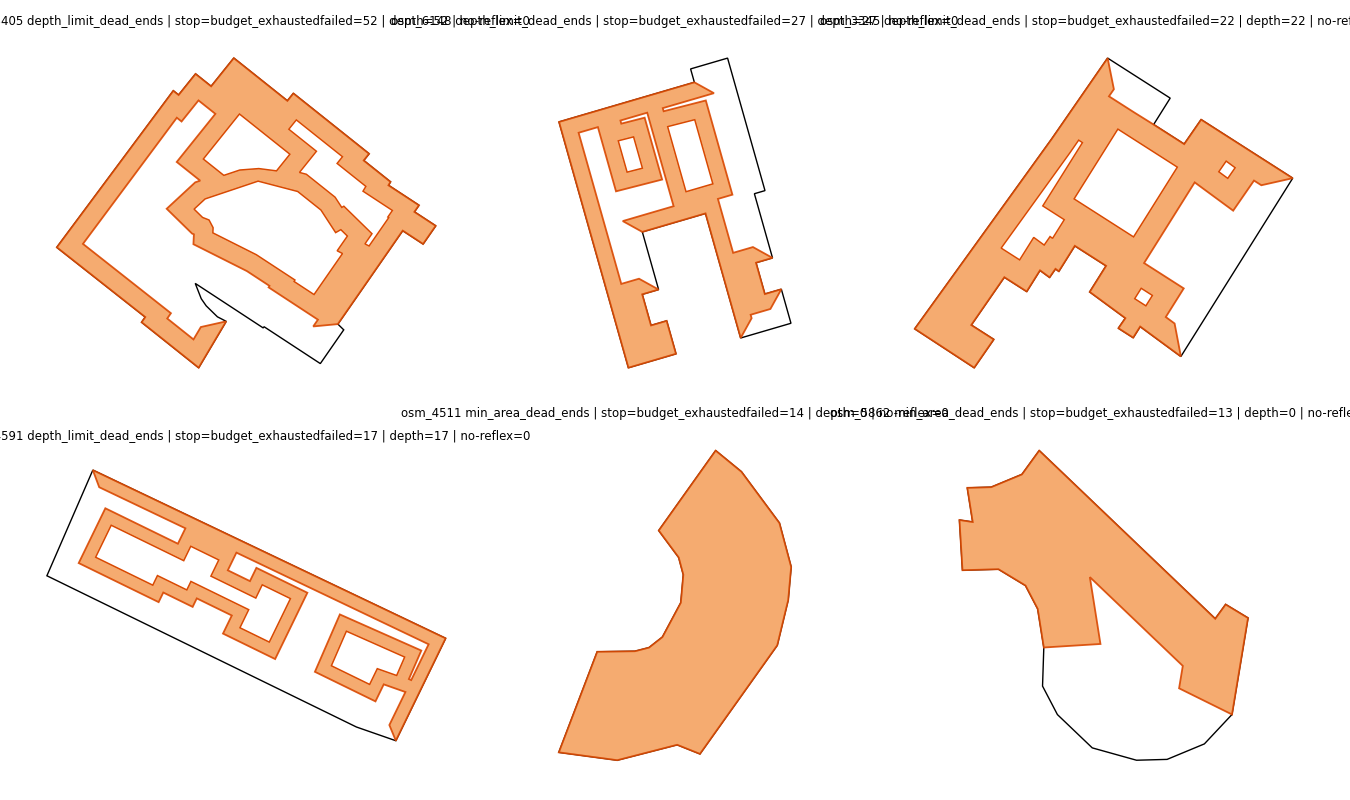

No small-zone polygons under the current configuration.


In [11]:
N_FAILURE_EXAMPLES = 6
N_SMALL_ZONE_EXAMPLES = 6

failed_examples = failed_polygon_gdf.sort_values(
    ['failure_reason', 'n_failed_terminal_states', 'n_states_seen'],
    ascending=[True, False, False],
).head(N_FAILURE_EXAMPLES)
small_zone_examples = small_zone_polygon_gdf.sort_values(
    ['best_min_part_area_m2', 'n_states_seen'],
    ascending=[True, False],
).head(N_SMALL_ZONE_EXAMPLES)

if failed_examples.empty:
    print('No failed polygons under the current configuration.')
else:
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8))
    axes = axes.flatten()
    for ax, (_, rec) in zip(axes, failed_examples.iterrows()):
        fill_polygon_geometry(ax, rec['building_geometry'], facecolor='none', edgecolor='black', linewidth=1.0)
        fill_polygon_geometry(ax, rec['geometry'], facecolor='#f4a261', edgecolor='#d94801', linewidth=1.3, alpha=0.9)
        set_geometry_frame(ax, rec['building_geometry'], min_pad=1.0, pad_ratio=0.08, hide_ticks=True)
        ax.set_title(
            f"{rec['sample_id']} {rec['failure_reason']} | stop={rec['search_terminated_by']}"
            f"failed={int(rec['n_failed_terminal_states'])} | depth={int(rec['n_depth_limit_dead_ends'])} | "
            f"no-reflex={int(rec['n_no_reflex_dead_ends'])}",
            fontsize=8.5,
        )
    for ax in axes[len(failed_examples):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

if small_zone_examples.empty:
    print('No small-zone polygons under the current configuration.')
else:
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8))
    axes = axes.flatten()
    for ax, (_, rec) in zip(axes, small_zone_examples.iterrows()):
        fill_polygon_geometry(ax, rec['building_geometry'], facecolor='none', edgecolor='black', linewidth=1.0)
        for part in parts_from_geom(rec['best_variant_geom']):
            area = getattr(part, 'area', 0.0)
            fill_polygon_geometry(
                ax,
                part,
                facecolor='#e76f51' if area < cfg.min_area_m2 else '#8ecae6',
                edgecolor='black',
                linewidth=0.6,
                alpha=0.95,
            )
        fill_polygon_geometry(ax, rec['geometry'], facecolor='none', edgecolor='#d94801', linewidth=1.2)
        set_geometry_frame(ax, rec['building_geometry'], min_pad=1.0, pad_ratio=0.08, hide_ticks=True)
        ax.set_title(
            f"{rec['sample_id']} min part={rec['best_min_part_area_m2']:.2f} m² | fallback={rec['fallback_used'] or 'none'}",
            fontsize=8.5,
        )
    for ax in axes[len(small_zone_examples):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


## Plot decomposition results
### Plot convex part-count distributions


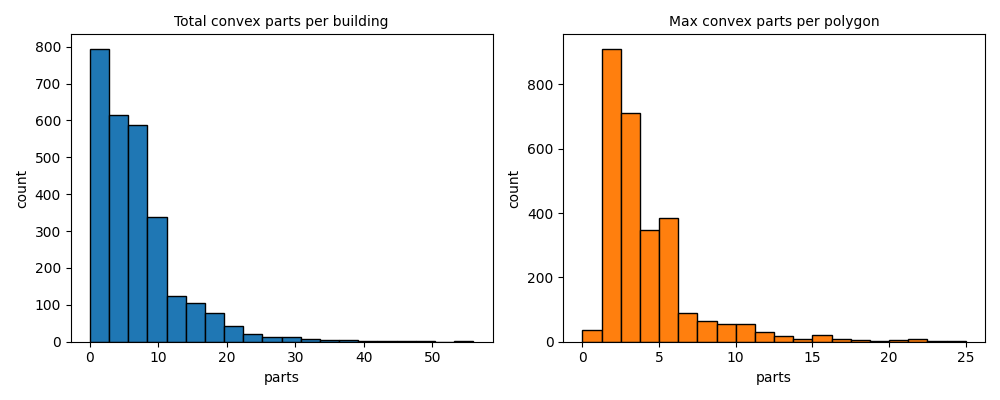

In [12]:
total_parts = buildings_convex_gdf['convex_parts_counts'].apply(lambda xs: int(sum(xs)) if isinstance(xs, list) else 0)
max_parts = buildings_convex_gdf['convex_parts_counts'].apply(lambda xs: int(max(xs)) if isinstance(xs, list) and xs else 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(total_parts, bins=20, color='#1f77b4', edgecolor='black')
axes[0].set_title('Total convex parts per building')
axes[0].set_xlabel('parts')
axes[0].set_ylabel('count')

axes[1].hist(max_parts, bins=20, color='#ff7f0e', edgecolor='black')
axes[1].set_title('Max convex parts per polygon')
axes[1].set_xlabel('parts')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()


### Plot vertex-binned success and runtime


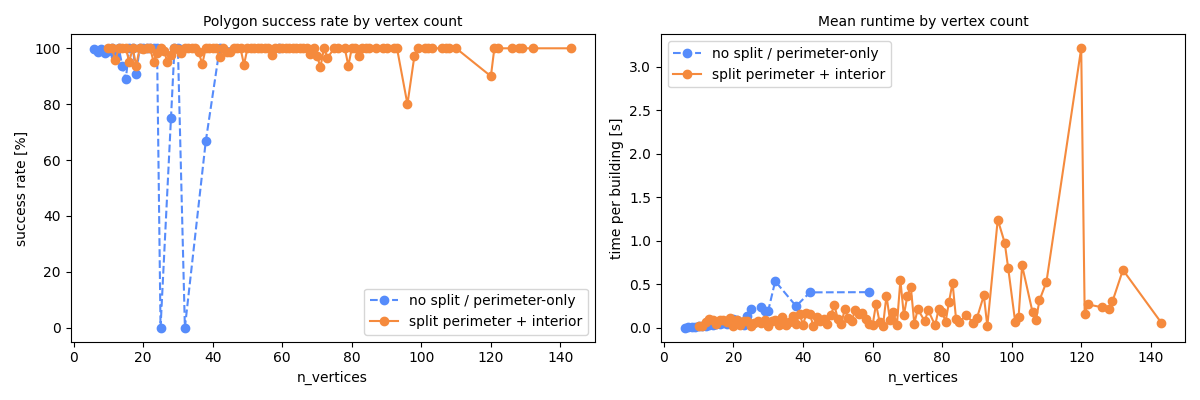

In [13]:
stats_plot_df = buildings_convex_gdf.copy()
stats_plot_df['perimeter_bool'] = stats_plot_df['perimeter'].fillna(False).astype(bool)
stats_plot_df['polygon_success_rate'] = stats_plot_df['polygon_fully_convex_flags'].apply(
    lambda flags: (sum(flags) / len(flags)) if isinstance(flags, list) and flags else np.nan
)

grouped = (
    stats_plot_df
    .groupby(['n_vertices', 'perimeter_bool'])[['polygon_success_rate', 'time_total_seconds']]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for is_perimeter, linestyle, label in [(False, '--', 'no split / perimeter-only'), (True, '-', 'split perimeter + interior')]:
    sub = grouped.loc[grouped['perimeter_bool'] == is_perimeter].sort_values('n_vertices')
    if sub.empty:
        continue
    axes[0].plot(sub['n_vertices'], 100.0 * sub['polygon_success_rate'], linestyle=linestyle, marker='o', label=label)
    axes[1].plot(sub['n_vertices'], sub['time_total_seconds'], linestyle=linestyle, marker='o', label=label)

axes[0].set_title('Polygon success rate by vertex count')
axes[0].set_xlabel('n_vertices')
axes[0].set_ylabel('success rate [%]')
axes[0].legend()

axes[1].set_title('Mean runtime by vertex count')
axes[1].set_xlabel('n_vertices')
axes[1].set_ylabel('time per building [s]')
axes[1].legend()

plt.tight_layout()
plt.show()


### Plot original versus convex comparison grids

**Inputs**
- `buildings_convex_gdf` with direct and perimeter-assisted convex decomposition results
- `select_complexity_ids`, `parts_from_geom`, and `GHSL_gridplot`

**Steps**
1. Select representative direct and perimeter-assisted samples across the exterior-vertex range.
2. Build ordered GeoDataFrame views for original outlines and convex-part overlays.
3. Plot four comparison grids: direct original, direct convex parts, perimeter original, and perimeter convex parts.
4. Save each rendered grid as a PDF under `tmp/osm_2_decomposition_exports/`.

**Outputs**
- Four displayed comparison grids
- PDF exports in `tmp/osm_2_decomposition_exports/`


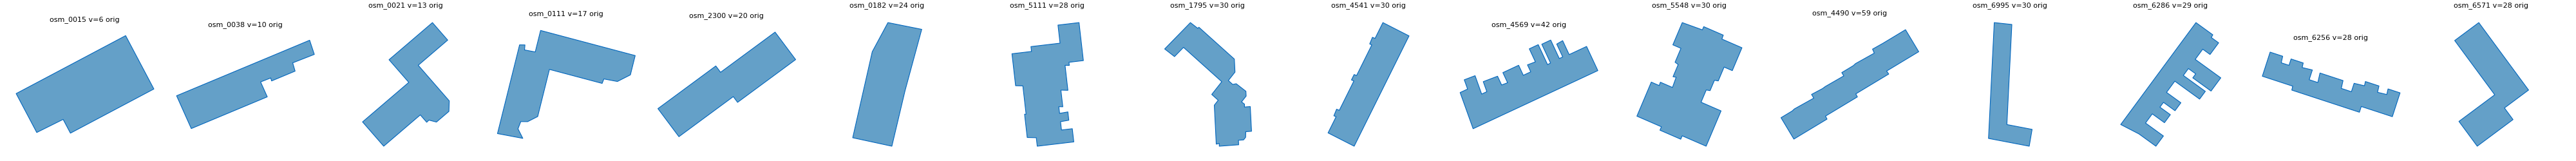

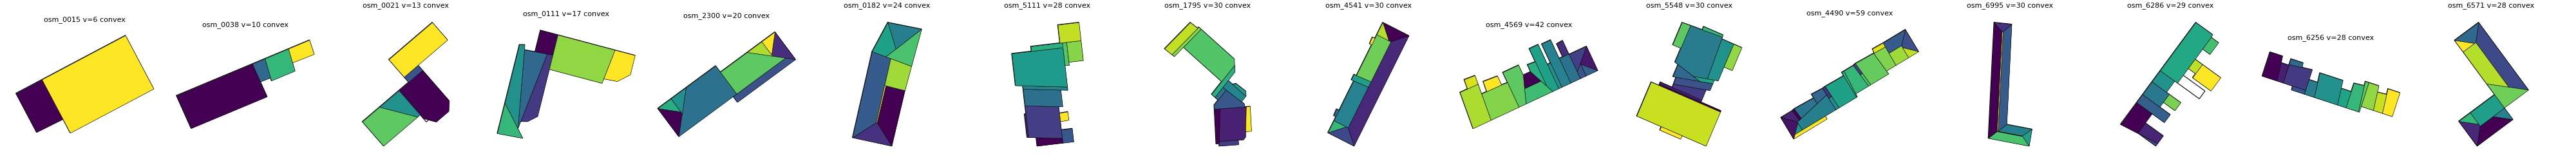

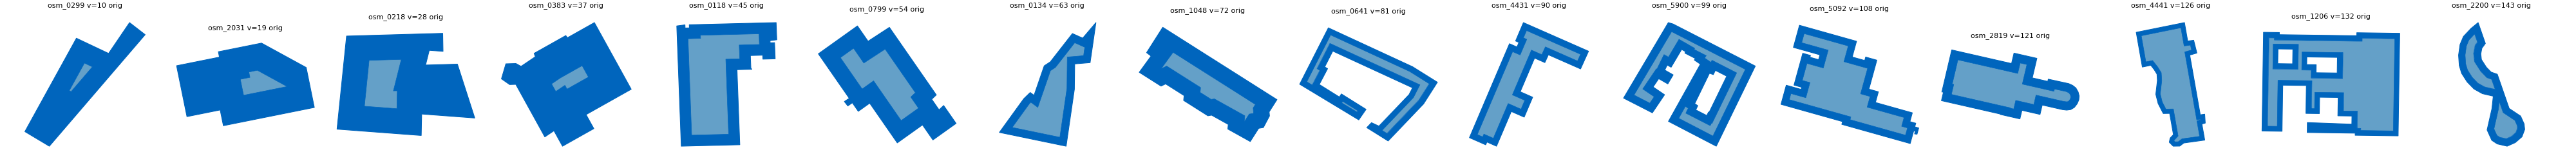

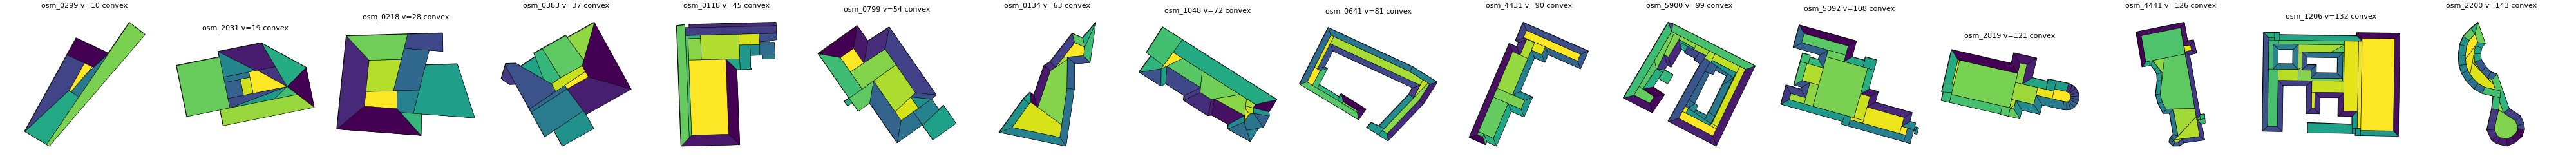

In [14]:
TUM_DARK = '#0065BD'
TUM_LIGHT = '#64A0C8'
N_COMPARE = 16
EXPORT_DIR = PROJECT_ROOT / 'tmp' / 'osm_2_decomposition_exports'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)


def save_current_grid_pdf(stem: str) -> None:
    fig = plt.gcf()
    fig.savefig(EXPORT_DIR / f'{stem}.pdf', bbox_inches='tight')


nonperim_ids = select_complexity_ids(buildings_convex_gdf, perimeter_flag=False, n_examples=N_COMPARE)
perim_ids_compare = select_complexity_ids(buildings_convex_gdf, perimeter_flag=True, n_examples=N_COMPARE)

nonperim = buildings_convex_gdf.loc[buildings_convex_gdf['sample_id'].isin(nonperim_ids)].copy()
nonperim['sample_id'] = nonperim['sample_id'].astype(str)
nonperim['order_idx'] = nonperim['sample_id'].map({sid: i for i, sid in enumerate(nonperim_ids)})
nonperim = nonperim.sort_values('order_idx')
nonperim_outline = gpd.GeoDataFrame(nonperim, geometry='geometry', crs=buildings_convex_gdf.crs)
nonperim_parts = nonperim.copy()
nonperim_parts['convex_parts_list'] = nonperim_parts['convex_parts_geom'].apply(parts_from_geom)
nonperim_lookup = nonperim.set_index('sample_id')

if nonperim_ids:
    GHSL_gridplot(
        [
            {
                'name': 'nonperim_original',
                'gdf': nonperim_outline,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': TUM_LIGHT,
                'edgecolor': TUM_DARK,
                'linewidth': 0.8,
            }
        ],
        ids=nonperim_ids,
        ncols=len(nonperim_ids),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(nonperim_lookup.loc[sid, 'n_vertices'])} orig",
    )
    save_current_grid_pdf('nonperim_original_grid')
    plt.show()

    GHSL_gridplot(
        [
            {
                'name': 'nonperim_outline',
                'gdf': nonperim_outline,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.8,
            },
            {
                'name': 'nonperim_convex_parts',
                'gdf': nonperim_parts,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'convex_parts_list',
                'cmap': 'viridis',
                'edgecolor': 'black',
                'linewidth': 0.4,
            },
        ],
        ids=nonperim_ids,
        ncols=len(nonperim_ids),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(nonperim_lookup.loc[sid, 'n_vertices'])} convex",
    )
    save_current_grid_pdf('nonperim_convex_grid')
    plt.show()

perim = buildings_convex_gdf.loc[buildings_convex_gdf['sample_id'].isin(perim_ids_compare)].copy()
perim['sample_id'] = perim['sample_id'].astype(str)
perim['order_idx'] = perim['sample_id'].map({sid: i for i, sid in enumerate(perim_ids_compare)})
perim = perim.sort_values('order_idx')
perim_shell = gpd.GeoDataFrame(perim, geometry='perimeter_geom', crs=buildings_convex_gdf.crs)
perim_interior = gpd.GeoDataFrame(perim.loc[perim['interior_geom'].notna()].copy(), geometry='interior_geom', crs=buildings_convex_gdf.crs)
perim_parts = perim.copy()
perim_parts['convex_parts_list'] = perim_parts['convex_parts_geom'].apply(parts_from_geom)
perim_lookup = perim.set_index('sample_id')

if perim_ids_compare:
    GHSL_gridplot(
        [
            {
                'name': 'perim_shell',
                'gdf': perim_shell,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'perimeter_geom',
                'color': TUM_DARK,
                'edgecolor': TUM_DARK,
                'linewidth': 0.8,
            },
            {
                'name': 'perim_interior',
                'gdf': perim_interior,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'interior_geom',
                'color': TUM_LIGHT,
                'edgecolor': TUM_DARK,
                'linewidth': 0.5,
            },
        ],
        ids=perim_ids_compare,
        ncols=len(perim_ids_compare),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(perim_lookup.loc[sid, 'n_vertices'])} orig",
    )
    save_current_grid_pdf('perim_original_grid')
    plt.show()

    GHSL_gridplot(
        [
            {
                'name': 'perim_outline',
                'gdf': perim_shell,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'perimeter_geom',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.8,
            },
            {
                'name': 'perim_convex_parts',
                'gdf': perim_parts,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'convex_parts_list',
                'cmap': 'viridis',
                'edgecolor': 'black',
                'linewidth': 0.4,
            },
        ],
        ids=perim_ids_compare,
        ncols=len(perim_ids_compare),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(perim_lookup.loc[sid, 'n_vertices'])} convex",
    )
    save_current_grid_pdf('perim_convex_grid')
    plt.show()


## Final pipeline summary

### Summarize convex coverage for the OSM working set

Report the final building-level counts from the current OSM decomposition run:
1. Buildings with at least one failed polygon decomposition.
2. Buildings whose decomposed output is fully convex.
3. Buildings whose decomposed output is fully convex and all zones are at least `cfg.min_area_m2`.
4. The retained building table `buildings_convex_gdf`, which keeps the full working set and adds decomposition diagnostics.

In [15]:
n_loaded = len(subset_buildings_gdf)
n_total = len(buildings_convex_gdf)

fully_convex_flags = buildings_convex_gdf['building_fully_convex'].fillna(False).astype(bool).to_numpy(dtype=bool)
failed_flags = buildings_convex_gdf['building_decomposition_failed'].fillna(False).astype(bool).to_numpy(dtype=bool)
small_zone_flags = buildings_convex_gdf['building_has_small_zone'].fillna(False).astype(bool).to_numpy(dtype=bool)
clean_convex_flags = fully_convex_flags & ~small_zone_flags

n_failed = int(np.sum(failed_flags))
n_fully_convex = int(np.sum(fully_convex_flags))
n_clean_convex = int(np.sum(clean_convex_flags))
n_small_zone = int(np.sum(small_zone_flags))

pct_failed = 100.0 * n_failed / n_total if n_total else 0.0
pct_fully_convex = 100.0 * n_fully_convex / n_total if n_total else 0.0
pct_clean_convex = 100.0 * n_clean_convex / n_total if n_total else 0.0
pct_small_zone = 100.0 * n_small_zone / n_total if n_total else 0.0
pct_retained = 100.0 * n_total / n_loaded if n_loaded else 0.0

print('=== Dataset-level pipeline summary ===')
print(f'Loaded preselected subset: {n_loaded}')
print(f'Buildings prepared for decomposition: {n_total} / {n_loaded} ({pct_retained:.1f}%)')
print(f'Buildings with at least one failed polygon decomposition: {n_failed} / {n_total} ({pct_failed:.1f}%)')
print(f'Fully convex after H/V decomposition: {n_fully_convex} / {n_total} ({pct_fully_convex:.1f}%)')
print(
    f'Fully convex and all zones >= {cfg.min_area_m2:.1f} m^2 after decomposition: '
    f'{n_clean_convex} / {n_total} ({pct_clean_convex:.1f}%)'
)
print(f'Buildings with any zone smaller than {cfg.min_area_m2:.1f} m^2: {n_small_zone} / {n_total} ({pct_small_zone:.1f}%)')
print(
    'Retained building table with decomposition diagnostics '
    f'(no extra post-decomposition geometry filter): {n_total} / {n_loaded} ({pct_retained:.1f}%)'
)


=== Dataset-level pipeline summary ===
Loaded preselected subset: 2755
Buildings prepared for decomposition: 2755 / 2755 (100.0%)
Buildings with at least one failed polygon decomposition: 56 / 2755 (2.0%)
Fully convex after H/V decomposition: 2699 / 2755 (98.0%)
Fully convex and all zones >= 2.0 m^2 after decomposition: 2699 / 2755 (98.0%)
Buildings with any zone smaller than 2.0 m^2: 0 / 2755 (0.0%)
Retained building table with decomposition diagnostics (no extra post-decomposition geometry filter): 2755 / 2755 (100.0%)


## Export zone provenance and boundary interfaces

The convex parts alone cannot say which of their walls exist in reality. This section records, for every part, which building and which prepared zone it came from, and classifies every boundary sub-segment it owns.

An OSM footprint is a single physical envelope, so the whole building is one space and the perimeter, trapezoid, corner, remainder, and interior pieces are zones inside it. A cut between two of those pieces is therefore reported as `zoning_split`, a deliberate thermal-zoning boundary, while a cut produced by the convex decomposition inside one piece is reported as `artificial_split`. Both are virtual, but only the second one is an artifact of the decomposition.

**Inputs**
- `polygon_results_gdf` with one row per prepared zone, its source polygon, and its convex parts
- `OSM_DATA_DIR` as the output location

**Steps**
1. Build one part record per convex part with its `container -> space -> zone -> part` chain.
2. Classify every boundary sub-segment against the neighbouring parts of the same building.
3. Report the aggregate counts, including unmatched segments that indicate an imperfect tiling.
4. Write the `zones` and `interfaces` layers to `data/osm/osm_zones.gpkg`.

**Outputs**
- `osm_parts`, `osm_interfaces`, `osm_zone_summary`
- `data/osm/osm_zones.gpkg`

**Used functions**
`osm_part_records`, `build_interfaces`, `summarize_interfaces`, `parts_to_geodataframe`, `interfaces_to_geodataframe`, `write_zone_artifacts`


In [ ]:
from convexdecomp.zones.adapters import osm_part_records
from convexdecomp.zones.export import (
    interfaces_to_geodataframe,
    parts_to_geodataframe,
    write_zone_artifacts,
)
from convexdecomp.zones.interfaces import (
    InterfaceConfig,
    build_interfaces,
    summarize_interfaces,
)

ZONE_INTERFACE_CFG = InterfaceConfig(tol=1e-6)

osm_parts = osm_part_records(polygon_results_gdf)
osm_interfaces = build_interfaces(osm_parts, ZONE_INTERFACE_CFG)
osm_zone_summary = summarize_interfaces(osm_parts, osm_interfaces)

print('=== OSM zone provenance ===')
print(f"Convex parts: {osm_zone_summary['n_parts']}")
print(f"Source spaces (buildings): {osm_zone_summary['n_spaces']}")
print(f"Spaces split into several parts: {osm_zone_summary['n_split_spaces']}")
print(f"Boundary segments: {osm_zone_summary['n_interfaces']}")
print(f"Virtual segments (artificial + zoning): {osm_zone_summary['n_virtual_interfaces']}")
print(f"Unmatched segments: {osm_zone_summary['n_unmatched']}")
print(f"Ambiguous segments: {osm_zone_summary['n_ambiguous']}")
print('')
print('Boundary length by kind [m]:')
for kind, length in sorted(osm_zone_summary['interface_length_by_kind'].items()):
    print(f'  {kind:20s} {length:12.2f}')

if osm_zone_summary['n_unmatched']:
    unmatched_length = osm_zone_summary['interface_length_by_kind'].get('unmatched', 0.0)
    total_length = sum(osm_zone_summary['interface_length_by_kind'].values())
    print('')
    print(
        f"Note: {osm_zone_summary['n_unmatched']} segments ({100.0 * unmatched_length / total_length:.2f}% of "
        'boundary length) have no neighbouring part and do not lie on their source zone boundary. '
        'They mark places where the decomposed parts do not tile their source zone exactly. '
        'Raise ZONE_INTERFACE_CFG.tol if they are numerical, or inspect them as geometry defects.'
    )

osm_zones_gdf = parts_to_geodataframe(osm_parts, crs=buildings_convex_gdf.crs)
osm_interfaces_gdf = interfaces_to_geodataframe(osm_interfaces, crs=buildings_convex_gdf.crs)

osm_zone_paths = write_zone_artifacts(
    osm_zones_gdf,
    osm_interfaces_gdf,
    OSM_DATA_DIR / 'osm_zones.gpkg',
)
print('')
for layer, path in osm_zone_paths.items():
    print(f'Wrote layer {layer} to {path}')
